# 02 · Document-type classifier (Phase 3, Part A)

**Goal:** recognise which of the 10 document types an uploaded image shows, and flag images the model is unsure
about as "unrecognized document". This is the first check in the KYC pipeline: later steps (forgery detection,
field extraction) depend on knowing the document type.

How it is built:
- **Data:** all 14,027 rows of `data/processed/manifest.csv`, with the Phase 2 train / validation / test split.
  Genuine and forged images both have a document type, so both are used. Images come only from the 512 px RGB
  cache (`cache_path`), never from the raw files (see CLAUDE.md, "Phase 2 findings").
- **Input:** 224 × 224 px. The document type is a global layout feature (colours, photo position, emblem), so a
  small input is enough. `resize_with_pad` keeps the aspect ratio and fills the rest with black bars.
- **Model:** EfficientNetB0 pretrained on ImageNet (transfer learning) plus a new 10-class softmax head.
  Stage 1 trains only the head; stage 2 also fine-tunes the top backbone layers with a 100× lower learning rate.
- **Evaluation:** the model is chosen on the validation split; the test split is used once, at the end.

Code: `src/ekyc/tfdata.py` (input pipeline), `src/ekyc/models.py` (model builder), tests in `tests/test_tfdata.py`.

In [1]:
import json
import os
import re
import shutil
import subprocess
import time

os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")  # hide TensorFlow's C++ info messages

import keras
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf
from IPython.display import display
from matplotlib.colors import LinearSegmentedColormap
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score

from ekyc import config, models, tfdata

keras.utils.set_random_seed(config.SEED)  # Python, NumPy and TensorFlow random seeds
ROOT = config.PROJECT_ROOT
REPORT_DIR = config.REPORTS_DIR / "phase3"
MODEL_DIR = ROOT / "models"

IMAGE_SIZE = 224
BATCH_SIZE = 32
CLASS_NAMES = list(config.DOC_TYPES)  # model output index i = CLASS_NAMES[i]
STAGE1 = {"learning_rate": 1e-3, "max_epochs": 15}
STAGE2 = {"learning_rate": 1e-5, "max_epochs": 15, "unfreeze_layers": 20}
PATIENCE = 3  # early stopping: stop after 3 epochs without a lower validation loss

# Chart style (validated colour-blind-safe palette).
SURFACE, INK, INK_2, MUTED, GRID, AXIS = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"


def style(ax, title):
    ax.set_facecolor(SURFACE)
    ax.set_title(title, loc="left", color=INK, fontsize=11)
    ax.tick_params(colors=MUTED, labelsize=9)
    ax.grid(axis="y", color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    for side in ("left", "bottom"):
        ax.spines[side].set_color(AXIS)


def peak_memory_gb():
    """Peak physical memory of this notebook's process so far, from macOS `footprint`.
    On Apple Silicon the GPU shares RAM with the CPU, so this includes the GPU's buffers."""
    out = subprocess.run(["footprint", "-p", str(os.getpid())], capture_output=True, text=True).stdout
    value, unit = re.search(r"phys_footprint_peak:\s*([\d.]+)\s*(KB|MB|GB)", out).groups()
    return float(value) * {"KB": 1 / 1024**2, "MB": 1 / 1024, "GB": 1}[unit]


def swap_used_gb():
    out = subprocess.run(["sysctl", "-n", "vm.swapusage"], capture_output=True, text=True).stdout
    return float(re.search(r"used = ([\d.]+)M", out).group(1)) / 1024


REPORT_DIR.mkdir(parents=True, exist_ok=True)
MODEL_DIR.mkdir(parents=True, exist_ok=True)
notebook_start = time.perf_counter()
tf.reduce_sum(tf.ones((2, 2))).numpy()  # first GPU operation: TensorFlow sets up the Metal device here
print(f"TensorFlow {tf.__version__} | Keras {keras.__version__} | GPU: {tf.config.list_physical_devices('GPU')}")
print(f"input {IMAGE_SIZE}x{IMAGE_SIZE}, batch {BATCH_SIZE}, stage 1 {STAGE1}, stage 2 {STAGE2}, patience {PATIENCE}")
print(f"swap in use at start: {swap_used_gb():.1f} GB")

TensorFlow 2.18.1 | Keras 3.15.1 | GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
input 224x224, batch 32, stage 1 {'learning_rate': 0.001, 'max_epochs': 15}, stage 2 {'learning_rate': 1e-05, 'max_epochs': 15, 'unfreeze_layers': 20}, patience 3
swap in use at start: 25.0 GB


I0000 00:00:1794745153.044834 35036165 pluggable_device_factory.cc:305] Could not identify NUMA node of platform GPU ID 0, defaulting to 0. Your kernel may not have been built with NUMA support.
I0000 00:00:1794745153.044851 35036165 pluggable_device_factory.cc:271] Created TensorFlow device (/job:localhost/replica:0/task:0/device:GPU:0 with 0 MB memory) -> physical PluggableDevice (device: 0, name: METAL, pci bus id: <undefined>)


**Setup.** TensorFlow uses the Apple M5 GPU through the Metal plugin. The log lines TensorFlow prints when the GPU
is first used (e.g. "Could not identify NUMA node") are harmless information messages. All random seeds are fixed (seed 42), but
GPU arithmetic is not perfectly deterministic, so a re-run can differ slightly in the last decimals. Stage 1 trains
the head with learning rate 0.001; stage 2 fine-tunes with 0.00001. Each stage runs at most 15 epochs and stops
early when the validation loss has not improved for 3 epochs.

In [2]:
splits = {name: tfdata.load_manifest(split=name) for name in ("train", "val", "test")}
counts = pd.DataFrame({name: df["doc_type"].value_counts() for name, df in splits.items()}).loc[CLASS_NAMES]
counts.loc["total"] = counts.sum()
display(counts)
train_counts = counts.loc[CLASS_NAMES, "train"]
print(f"largest / smallest training class: {train_counts.max()} / {train_counts.min()} = {train_counts.max() / train_counts.min():.2f}")

train_ds = tfdata.make_dataset(splits["train"], "doc_type", CLASS_NAMES, IMAGE_SIZE, BATCH_SIZE, training=True)
val_ds = tfdata.make_dataset(splits["val"], "doc_type", CLASS_NAMES, IMAGE_SIZE, BATCH_SIZE)
print("one element of the training dataset:", train_ds.element_spec)

,train,val,test
doc_type,,,
alb_id,957,180,205
aze_passport,964,186,254
esp_id,1223,190,238
est_id,947,179,214
fin_id,989,193,159
grc_passport,992,270,139
lva_passport,965,213,224
rus_internalpassport,967,256,182
srb_passport,1024,233,143


largest / smallest training class: 1223 / 919 = 1.33
one element of the training dataset: (TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None,), dtype=tf.int32, name=None))


**Data.** Every image in the training manifest is used, genuine and forged alike, with the Phase 2 split
(9,947 train / 2,118 validation / 1,962 test images). The classes are close to balanced: the largest training
class (esp_id, 1,223 images) is only 1.33 times the smallest (svk_id, 919), so no class weights are used for this
model; the macro F1 score (the average F1 over the 10 classes) is reported to make sure no class is neglected.
The pipeline yields batches of 32 images of 224 × 224 × 3 (float32, pixel values 0–255) with an integer label
0–9, the position of the document type in `CLASS_NAMES`.

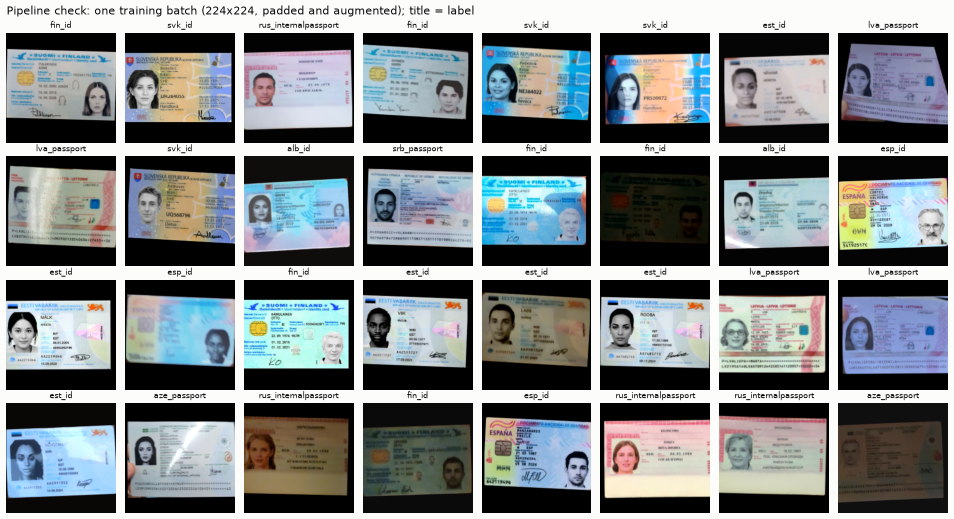

batch (32, 224, 224, 3), float32, pixel range 0-255


In [3]:
images, labels = next(iter(train_ds))
fig, axes = plt.subplots(4, 8, figsize=(16, 8.8), dpi=60, facecolor=SURFACE)
for ax, image, label in zip(axes.flat, images.numpy(), labels.numpy()):
    ax.imshow(image.astype("uint8"))
    ax.set_title(CLASS_NAMES[label], fontsize=10, color=INK)
    ax.axis("off")
fig.suptitle(f"Pipeline check: one training batch ({IMAGE_SIZE}x{IMAGE_SIZE}, padded and augmented); title = label",
             x=0.01, ha="left", color=INK, fontsize=13)
fig.tight_layout()
fig.savefig(REPORT_DIR / "pipeline_check.png", dpi=90, facecolor=SURFACE)
plt.show()
print(f"batch {tuple(images.shape)}, {images.dtype.name}, pixel range {images.numpy().min():.0f}-{images.numpy().max():.0f}")

<!-- id: pipeline -->
**Pipeline check.** One training batch exactly as the model receives it (saved as `reports/phase3/pipeline_check.png`).
Every title matches the document shown (Finnish ID = fin_id, Latvian passport = lva_passport, and so on), so images
and labels are correctly paired. Each card keeps its shape inside the 224 × 224 square, with black bars, and the
small random tilts and shifts are visible; no text is mirrored. Most of the batch are video frames (84 % of the
training images), with real glare, dim light and slight blur: the variation the model has to cope with. Pixel
values are 0–255, as EfficientNet expects.

In [4]:
model, backbone = models.build_doc_classifier(len(CLASS_NAMES), IMAGE_SIZE)


def n_params(weights):
    return int(sum(np.prod(w.shape) for w in weights))


print(f"backbone: EfficientNetB0, {len(backbone.layers)} layers, ImageNet weights, frozen")
print(f"parameters: {model.count_params():,} in total, {n_params(model.trainable_weights):,} trainable (the head)")

backbone: EfficientNetB0, 239 layers, ImageNet weights, frozen
parameters: 4,062,381 in total, 12,810 trainable (the head)


**Model.** EfficientNetB0 turns each image into 1,280 features; on top sit a dropout layer (20 %, against
overfitting) and a dense softmax layer with 10 outputs, one probability per document type. In stage 1 the backbone
is frozen, so only the head's 12,810 weights (1,280 × 10 + 10 biases) are trained; the 4 million pretrained
backbone weights stay as learned on ImageNet. The backbone has its own rescaling and normalisation layers, which is
why the pipeline feeds it raw 0–255 pixels.

In [5]:
model.compile(optimizer=keras.optimizers.Adam(STAGE1["learning_rate"]),
              loss="sparse_categorical_crossentropy", metrics=["accuracy"])
callbacks1 = models.training_callbacks(MODEL_DIR / "doc_classifier_stage1.keras",
                                       REPORT_DIR / "doc_classifier_stage1_log.csv", PATIENCE)
# shuffle=False: the tf.data pipeline already reshuffles the training set every epoch.
history1 = model.fit(train_ds, validation_data=val_ds, epochs=STAGE1["max_epochs"], callbacks=callbacks1,
                     shuffle=False, verbose=2)
stage1_seconds = callbacks1[-1].seconds
print(f"\nstage 1: {len(stage1_seconds)} epochs in {sum(stage1_seconds) / 60:.1f} min, "
      f"{np.mean(stage1_seconds):.0f} s per epoch on average (training + validation)")
val_loss_now, _ = model.evaluate(val_ds, verbose=0)
print(f"best val_loss during stage 1: {min(history1.history['val_loss']):.4f} | val_loss of the model now: {val_loss_now:.4f}")

Epoch 1/15


311/311 - 67s - 215ms/step - accuracy: 0.9188 - loss: 0.5466 - val_accuracy: 0.9764 - val_loss: 0.2003


Epoch 2/15


311/311 - 89s - 285ms/step - accuracy: 0.9880 - loss: 0.1050 - val_accuracy: 0.9830 - val_loss: 0.1081


Epoch 3/15


311/311 - 91s - 294ms/step - accuracy: 0.9936 - loss: 0.0597 - val_accuracy: 0.9854 - val_loss: 0.0754


... (23 outputs left out)

311/311 - 113s - 365ms/step - accuracy: 0.9972 - loss: 0.0129 - val_accuracy: 0.9901 - val_loss: 0.0415


Restoring model weights from the end of the best epoch: 14.



stage 1: 15 epochs in 25.5 min, 102 s per epoch on average (training + validation)


best val_loss during stage 1: 0.0391 | val_loss of the model now: 0.0391


<!-- id: stage1 -->
**Stage 1 — training the head.** Validation accuracy was 97.6 % after the first epoch and 99.0 % by epoch 7: the
ImageNet features already separate the document types well, and only the last layer had to learn the mapping. The
validation loss kept falling slowly, so early stopping never triggered and all 15 epochs ran. The best epoch
(14: validation loss 0.0391, accuracy 99.0 %) was restored and saved to `models/doc_classifier_stage1.keras`; the
last line confirms that the restored model has exactly that loss. Training accuracy (99.7 %) is measured on
augmented images with dropout switched on, so it is not directly comparable with validation accuracy, but the
small gap shows no sign of overfitting.

*Time per epoch:* 67 s for the first epoch, then 85–140 s (102 s on average). The slowdown follows the machine's
memory pressure (swap use rose from 25 GB to over 28 GB during the run, with other applications and unrelated
Docker containers running), not the model itself.

In [6]:
n_unfrozen = models.unfreeze_top_layers(backbone, STAGE2["unfreeze_layers"])
model.compile(optimizer=keras.optimizers.Adam(STAGE2["learning_rate"]),  # re-compile after changing trainable
              loss="sparse_categorical_crossentropy", metrics=["accuracy"])
print(f"unfrozen: {n_unfrozen} of the top {STAGE2['unfreeze_layers']} backbone layers (BatchNormalization stays frozen); "
      f"trainable parameters now {n_params(model.trainable_weights):,}\n")
callbacks2 = models.training_callbacks(MODEL_DIR / "doc_classifier_stage2.keras",
                                       REPORT_DIR / "doc_classifier_stage2_log.csv", PATIENCE)
history2 = model.fit(train_ds, validation_data=val_ds, epochs=STAGE2["max_epochs"], callbacks=callbacks2,
                     shuffle=False, verbose=2)
stage2_seconds = callbacks2[-1].seconds
print(f"\nstage 2: {len(stage2_seconds)} epochs in {sum(stage2_seconds) / 60:.1f} min, "
      f"{np.mean(stage2_seconds):.0f} s per epoch on average (training + validation)")

unfrozen: 15 of the top 20 backbone layers (BatchNormalization stays frozen); trainable parameters now 1,134,394

Epoch 1/15


311/311 - 118s - 379ms/step - accuracy: 0.9972 - loss: 0.0109 - val_accuracy: 0.9896 - val_loss: 0.0375


Epoch 2/15


311/311 - 126s - 404ms/step - accuracy: 0.9970 - loss: 0.0096 - val_accuracy: 0.0000e+00 - val_loss: nan


Epoch 3/15


311/311 - 96s - 309ms/step - accuracy: 0.0000e+00 - loss: nan - val_accuracy: 0.0000e+00 - val_loss: nan


Epoch 4/15


311/311 - 113s - 363ms/step - accuracy: 0.0000e+00 - loss: nan - val_accuracy: 0.0000e+00 - val_loss: nan


Epoch 4: early stopping


Restoring model weights from the end of the best epoch: 1.



stage 2: 4 epochs in 7.5 min, 113 s per epoch on average (training + validation)


<!-- id: stage2 -->
**Stage 2 — fine-tuning, and a numerical failure.** The top 20 backbone layers were unfrozen except their 5
BatchNormalization layers (15 layers, 1.13 million trainable parameters) and trained with a learning rate of
0.00001. The first epoch lowered the validation loss to 0.0375, the best value of the whole run, and was saved to
`models/doc_classifier_stage2.keras`. In the second epoch the validation loss became `NaN` ("not a number"), and from
the third epoch the training loss as well: the weights had become invalid. With such a low learning rate and a
healthy previous epoch, this is not ordinary divergence; the cause has not been pinned down (the most likely
candidates are a numerical fault in the GPU computation via the Metal plugin, or the extreme memory pressure at the
time).

The safeguards worked as intended: a `NaN` never counts as an improvement, so the checkpoint kept epoch 1, and
early stopping ended the stage after three bad epochs and restored the epoch-1 weights. For the next models
(Part B), a `TerminateOnNaN` callback and gradient clipping should be added so that such a run stops at once.

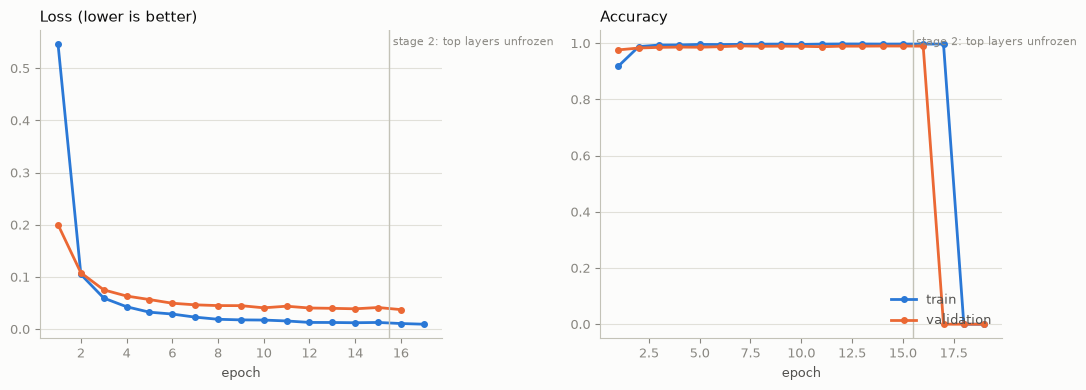

,stage,epoch,loss,accuracy,val_loss,val_accuracy
0,1,1,0.5466,0.9188,0.2003,0.9764
1,1,2,0.1050,0.9880,0.1081,0.9830
2,1,3,0.0597,0.9936,0.0754,0.9854
3,1,4,0.0430,0.9940,0.0635,0.9863
4,1,5,0.0326,0.9958,0.0568,0.9858
5,1,6,0.0290,0.9954,0.0497,0.9877
6,1,7,0.0231,0.9960,0.0467,0.9906
7,1,8,0.0190,0.9968,0.0452,0.9891
8,1,9,0.0179,0.9970,0.0451,0.9896
9,1,10,0.0175,0.9960,0.0410,0.9891


In [7]:
log = pd.concat([pd.read_csv(REPORT_DIR / f"doc_classifier_stage{s}_log.csv").assign(stage=s) for s in (1, 2)],
                ignore_index=True)
log["epoch"] = np.arange(1, len(log) + 1)  # count epochs across both stages
boundary = (log["stage"] == 1).sum() + 0.5

fig, axes = plt.subplots(1, 2, figsize=(11, 4), dpi=100, facecolor=SURFACE)
for ax, metric, title in [(axes[0], "loss", "Loss (lower is better)"), (axes[1], "accuracy", "Accuracy")]:
    ax.plot(log["epoch"], log[metric], color=BLUE, linewidth=2, marker="o", markersize=4, label="train")
    ax.plot(log["epoch"], log[f"val_{metric}"], color=ORANGE, linewidth=2, marker="o", markersize=4, label="validation")
    ax.axvline(boundary, color=AXIS, linewidth=1)
    ax.text(boundary + 0.15, 0.98, "stage 2: top layers unfrozen", transform=ax.get_xaxis_transform(),
            color=MUTED, fontsize=8, va="top")
    style(ax, title)
    ax.set_xlabel("epoch", color=INK_2, fontsize=9)
axes[1].legend(frameon=False, labelcolor=INK_2, fontsize=9, loc="lower right")
fig.tight_layout()
fig.savefig(REPORT_DIR / "doc_classifier_training_curves.png", dpi=150, facecolor=SURFACE)
plt.show()
display(log[["stage", "epoch", "loss", "accuracy", "val_loss", "val_accuracy"]].round(4))

<!-- id: curves -->
**Training curves.** Both losses drop steeply in the first three epochs and then flatten; the validation loss
stays close to the training loss, so the model generalises rather than memorising the training images. The
vertical line marks the start of stage 2: one healthy epoch, then the collapse to accuracy 0 (the `NaN` epochs,
which the loss panel shows as missing points). The legend partly covers that collapse in the accuracy panel; the
table below lists every value.

In [8]:
y_val = splits["val"]["doc_type"].map({name: i for i, name in enumerate(CLASS_NAMES)}).to_numpy()
candidates = {}
for stage in (1, 2):
    candidate = keras.models.load_model(MODEL_DIR / f"doc_classifier_stage{stage}.keras")
    proba = candidate.predict(val_ds, verbose=0)
    candidates[stage] = {
        "model": candidate, "proba": proba,
        "val_accuracy": accuracy_score(y_val, proba.argmax(axis=1)),
        "val_macro_f1": f1_score(y_val, proba.argmax(axis=1), average="macro"),
        "val_loss": float(np.mean(keras.losses.sparse_categorical_crossentropy(y_val, proba))),
    }
display(pd.DataFrame({f"stage {s}": {k: v for k, v in c.items() if k.startswith("val_")}
                      for s, c in candidates.items()}).T.round(4))

# Highest macro F1 wins; on a tie, the lower validation loss (better-calibrated probabilities).
chosen_stage = max(candidates, key=lambda s: (round(candidates[s]["val_macro_f1"], 4), -candidates[s]["val_loss"]))
best_model, val_proba = candidates[chosen_stage]["model"], candidates[chosen_stage]["proba"]
shutil.copy(MODEL_DIR / f"doc_classifier_stage{chosen_stage}.keras", MODEL_DIR / "doc_classifier.keras")
print(f"chosen: stage {chosen_stage} -> models/doc_classifier.keras")

,val_accuracy,val_macro_f1,val_loss
stage 1,0.9901,0.9900,0.0391
stage 2,0.9896,0.9896,0.0375


chosen: stage 1 -> models/doc_classifier.keras


<!-- id: choose -->
**Choosing the model on validation.** Both saved checkpoints were reloaded from disk and scored on the validation
split. They are practically equal: stage 1 classifies one more validation image correctly (accuracy 99.01 % vs
98.96 %, macro F1 0.9900 vs 0.9896), while stage 2 has a slightly lower loss. The rule fixed in advance (highest
macro F1; loss only breaks ties) selects **stage 1**, which is copied to `models/doc_classifier.keras`. Fine-tuning
therefore added nothing measurable: the frozen ImageNet features are already enough to recognise the document
layout.

In [9]:
GROUP = ["source", "label"]


def with_predictions(df, proba):
    out = df.assign(pred=[CLASS_NAMES[i] for i in proba.argmax(axis=1)], confidence=proba.max(axis=1))
    out["correct"] = out["pred"] == out["doc_type"]
    out["label"] = out["label"].map({0: "genuine", 1: "forged"})
    return out


def accuracy_by_group(df):
    return df.groupby(GROUP)["correct"].agg(images="size", accuracy="mean")


val = with_predictions(splits["val"], val_proba)
report_val = pd.DataFrame(classification_report(val["doc_type"], val["pred"], labels=CLASS_NAMES,
                                                output_dict=True, zero_division=0)).T
report_val.to_csv(REPORT_DIR / "doc_classifier_report_val.csv")
display(report_val.round(4))
display(accuracy_by_group(val).round(4))
errors_val = val.loc[~val["correct"], ["cache_path", "source", "label", "doc_type", "pred", "confidence"]]
print(f"misclassified validation images: {len(errors_val)} of {len(val)}")
display(errors_val.head(20))

,precision,recall,f1-score,support
alb_id,0.9944,0.9778,0.9860,180.0000
aze_passport,0.9945,0.9785,0.9864,186.0000
esp_id,0.9794,1.0000,0.9896,190.0000
est_id,0.9944,0.9888,0.9916,179.0000
fin_id,1.0000,1.0000,1.0000,193.0000
grc_passport,0.9926,1.0000,0.9963,270.0000
lva_passport,0.9769,0.9906,0.9837,213.0000
rus_internalpassport,0.9960,0.9648,0.9802,256.0000
srb_passport,0.9957,1.0000,0.9979,233.0000
svk_id,0.9776,1.0000,0.9887,218.0000


images  accuracy
source   label                    
clip     forged      589    0.9830
         genuine    1200    0.9908
template forged      179    1.0000
         genuine     150    1.0000

misclassified validation images: 21 of 2118


,cache_path,source,label,doc_type,pred,confidence
358,data/processed/images/clips_cropped/Images/rea...,clip,genuine,alb_id,lva_passport,0.582887
359,data/processed/images/clips_cropped/Images/rea...,clip,genuine,alb_id,lva_passport,0.297970
360,data/processed/images/clips_cropped/Images/rea...,clip,genuine,alb_id,est_id,0.672208
505,data/processed/images/clips_cropped/Images/rea...,clip,genuine,aze_passport,lva_passport,0.371963
506,data/processed/images/clips_cropped/Images/rea...,clip,genuine,aze_passport,lva_passport,0.430501
509,data/processed/images/clips_cropped/Images/rea...,clip,genuine,aze_passport,grc_passport,0.815766
539,data/processed/images/clips_cropped/Images/rea...,clip,genuine,aze_passport,srb_passport,0.510793
738,data/processed/images/clips_cropped/Images/rea...,clip,genuine,est_id,lva_passport,0.457765
751,data/processed/images/clips_cropped/Images/rea...,clip,genuine,est_id,alb_id,0.353202
1113,data/processed/images/clips_cropped/Images/rea...,clip,genuine,lva_passport,grc_passport,0.331786


<!-- id: val -->
**Validation results (chosen model).** 2,097 of 2,118 images (99.0 %) are classified correctly, and every class
has an F1 score of at least 0.98 (macro F1 0.990). All 329 templates are correct; all 21 errors are video frames.
They are concentrated in a few videos: 8 come from one forged Russian passport video with strong glare, which the
model mistakes for esp_id or svk_id. All errors have low confidence (median 0.47, next cell). A check of the
misclassified frames after the run showed that at least 8 of them contain no document at all: the dataset's
automatic crop missed the card and left a black or blank frame (see the summary).

,images,median confidence,rejected (confidence < threshold)
"validation, correctly classified",2097,0.9996,0.0095
"validation, misclassified",21,0.4713,0.9048
LFW face photos (not documents),200,0.5334,0.8350


suggested confidence threshold: 0.77


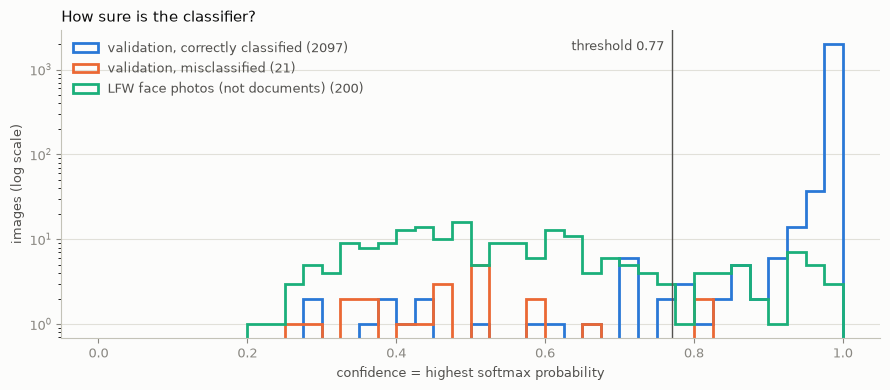

In [10]:
REJECT_BUDGET = 0.01  # accept losing at most 1 % of correctly recognised documents to the reject rule
correct_conf = val.loc[val["correct"], "confidence"].to_numpy()
wrong_conf = val.loc[~val["correct"], "confidence"].to_numpy()
# Threshold = 1st percentile of the confidence of correct predictions, rounded DOWN to 2 decimals.
threshold = float(np.floor(np.quantile(correct_conf, REJECT_BUDGET) * 100) / 100)

# Sanity probe for "not a document": 200 face photos from LFW (read-only, data/raw), evenly picked.
lfw_files = sorted((config.RAW_DIR / "lfw" / "lfw_home" / "lfw_funneled").rglob("*.jpg"))
lfw_files = lfw_files[:: len(lfw_files) // 200][:200]
lfw_conf = best_model.predict(tfdata.make_dataset_from_paths(lfw_files, IMAGE_SIZE), verbose=0).max(axis=1)

groups = {"validation, correctly classified": correct_conf, "validation, misclassified": wrong_conf,
          "LFW face photos (not documents)": lfw_conf}
confidence_table = pd.DataFrame({
    "images": {k: len(v) for k, v in groups.items()},
    "median confidence": {k: np.median(v) if len(v) else np.nan for k, v in groups.items()},
    "rejected (confidence < threshold)": {k: np.mean(v < threshold) if len(v) else np.nan for k, v in groups.items()},
})
display(confidence_table.round(4))
print(f"suggested confidence threshold: {threshold:.2f}")

fig, ax = plt.subplots(figsize=(9, 4), dpi=100, facecolor=SURFACE)
bins = np.linspace(0, 1, 41)
for (name, values), color in zip(groups.items(), (BLUE, ORANGE, AQUA)):
    if len(values):
        ax.hist(values, bins=bins, histtype="step", linewidth=2, color=color, label=f"{name} ({len(values)})")
ax.axvline(threshold, color=INK_2, linewidth=1)
ax.text(threshold - 0.01, 0.97, f"threshold {threshold:.2f}", transform=ax.get_xaxis_transform(),
        ha="right", va="top", color=INK_2, fontsize=9)
ax.set_yscale("log")
ax.set_xlabel("confidence = highest softmax probability", color=INK_2, fontsize=9)
ax.set_ylabel("images (log scale)", color=INK_2, fontsize=9)
style(ax, "How sure is the classifier?")
ax.legend(frameon=False, labelcolor=INK_2, fontsize=9, loc="upper left")
fig.tight_layout()
fig.savefig(REPORT_DIR / "doc_classifier_confidence.png", dpi=150, facecolor=SURFACE)
plt.show()

<!-- id: threshold -->
**Confidence threshold for "unrecognized document".** A prediction's confidence is its highest softmax probability.
On validation, correct predictions are almost always near-certain (median 0.9996), while errors are unsure (median
0.47). The threshold is set so that at most 1 % of correctly recognised documents are rejected: the 1st percentile
of their confidence, rounded down, gives **0.77**. At this threshold 0.95 % of the correct validation predictions
but 90 % of the errors (19 of 21) fall below it, and would go to "unrecognized document" (manual review) instead of
continuing with a wrong type.

As a rough test with images that are not documents at all, 200 face photos from LFW were classified: 83.5 % are
rejected, but 16.5 % receive a document type with high confidence. This is a known limitation of softmax
confidence: it measures how clearly an image belongs to one class rather than another, not whether it looks like
any training image. The threshold is a useful safety net, not a document detector; the pipeline should combine it
with the other checks (face match, extracted fields) before trusting an upload.

In [11]:
metadata = {
    "class_names": CLASS_NAMES,
    "input_size": IMAGE_SIZE,
    "confidence_threshold": threshold,
    "reject_rule": "if the highest softmax probability < confidence_threshold, report 'unrecognized document'",
    "preprocessing": "RGB JPEG -> tf.image.resize_with_pad(input_size, input_size); float32 pixels 0-255 "
                     "(EfficientNet rescales internally; do not divide by 255)",
    "chosen_stage": chosen_stage,
    "val_accuracy": round(float(candidates[chosen_stage]["val_accuracy"]), 4),
    "val_macro_f1": round(float(candidates[chosen_stage]["val_macro_f1"]), 4),
}
(MODEL_DIR / "doc_classifier.json").write_text(json.dumps(metadata, indent=2))
print(json.dumps(metadata, indent=2))

{
  "class_names": [
    "alb_id",
    "aze_passport",
    "esp_id",
    "est_id",
    "fin_id",
    "grc_passport",
    "lva_passport",
    "rus_internalpassport",
    "srb_passport",
    "svk_id"
  ],
  "input_size": 224,
  "confidence_threshold": 0.7699999809265137,
  "reject_rule": "if the highest softmax probability < confidence_threshold, report 'unrecognized document'",
  "preprocessing": "RGB JPEG -> tf.image.resize_with_pad(input_size, input_size); float32 pixels 0-255 (EfficientNet rescales internally; do not divide by 255)",
  "chosen_stage": 1,
  "val_accuracy": 0.9901,
  "val_macro_f1": 0.99
}


**Saved model.** `models/doc_classifier.keras` is the chosen model and `models/doc_classifier.json` holds what the
pipeline needs to use it: the class names in output order, the input size, the preprocessing and the confidence
threshold. The document worker in Phase 6 will load these two files. (`models/` is not committed to git because
of its size; the same information is also stored in `reports/phase3/doc_classifier_metrics.json`.) The threshold is printed as 0.7699999809 because it was computed in 32-bit floating point; it is 0.77.

In [12]:
# The ONLY use of the test split for this model.
test_ds = tfdata.make_dataset(splits["test"], "doc_type", CLASS_NAMES, IMAGE_SIZE, BATCH_SIZE)
test = with_predictions(splits["test"], best_model.predict(test_ds, verbose=0))
test_accuracy = accuracy_score(test["doc_type"], test["pred"])
test_macro_f1 = f1_score(test["doc_type"], test["pred"], labels=CLASS_NAMES, average="macro")
print(f"TEST: accuracy {test_accuracy:.4f} | macro F1 {test_macro_f1:.4f} | {len(test)} images")

report_test = pd.DataFrame(classification_report(test["doc_type"], test["pred"], labels=CLASS_NAMES,
                                                 output_dict=True, zero_division=0)).T
report_test.to_csv(REPORT_DIR / "doc_classifier_report_test.csv")
display(report_test.round(4))
by_group = pd.concat({"val": accuracy_by_group(val), "test": accuracy_by_group(test)}, axis=1)
by_group.to_csv(REPORT_DIR / "doc_classifier_accuracy_by_source_label.csv")
display(by_group.round(4))

rejected = test["confidence"] < threshold
print(f"reject rule on test: {rejected.sum()} of {len(test)} images ({rejected.mean():.2%}) below {threshold:.2f}; "
      f"accuracy on the accepted images {test.loc[~rejected, 'correct'].mean():.4f}")
errors_test = test.loc[~test["correct"], ["cache_path", "source", "label", "doc_type", "pred", "confidence"]]
print(f"misclassified test images: {len(errors_test)}")
display(errors_test.head(20))

TEST: accuracy 0.9929 | macro F1 0.9934 | 1962 images


,precision,recall,f1-score,support
alb_id,1.0000,0.9756,0.9877,205.0000
aze_passport,1.0000,0.9803,0.9901,254.0000
esp_id,1.0000,0.9958,0.9979,238.0000
est_id,1.0000,1.0000,1.0000,214.0000
fin_id,1.0000,1.0000,1.0000,159.0000
grc_passport,0.9929,1.0000,0.9964,139.0000
lva_passport,0.9451,1.0000,0.9718,224.0000
rus_internalpassport,1.0000,1.0000,1.0000,182.0000
srb_passport,1.0000,0.9860,0.9930,143.0000
svk_id,1.0000,0.9951,0.9975,204.0000


val            test         
                 images accuracy images accuracy
source   label                                  
clip     forged     589   0.9830    440   0.9977
         genuine   1200   0.9908   1184   0.9890
template forged     179   1.0000    190   1.0000
         genuine    150   1.0000    148   1.0000

reject rule on test: 29 of 1962 images (1.48%) below 0.77; accuracy on the accepted images 1.0000
misclassified test images: 14


,cache_path,source,label,doc_type,pred,confidence
388,data/processed/images/clips_cropped/Images/rea...,clip,genuine,alb_id,lva_passport,0.402585
389,data/processed/images/clips_cropped/Images/rea...,clip,genuine,alb_id,lva_passport,0.536030
390,data/processed/images/clips_cropped/Images/rea...,clip,genuine,alb_id,lva_passport,0.630817
391,data/processed/images/clips_cropped/Images/rea...,clip,genuine,alb_id,lva_passport,0.660575
401,data/processed/images/clips_cropped/Images/rea...,clip,genuine,alb_id,lva_passport,0.601900
545,data/processed/images/clips_cropped/Images/rea...,clip,genuine,aze_passport,lva_passport,0.391886
551,data/processed/images/clips_cropped/Images/rea...,clip,genuine,aze_passport,lva_passport,0.366040
581,data/processed/images/clips_cropped/Images/rea...,clip,genuine,aze_passport,lva_passport,0.362664
609,data/processed/images/clips_cropped/Images/rea...,clip,genuine,aze_passport,lva_passport,0.578436
697,data/processed/images/clips_cropped/Images/rea...,clip,genuine,esp_id,lva_passport,0.461819


<!-- id: test -->
**Test results — the single use of the test split.** On 1,962 unseen images the classifier reaches **99.29 %
accuracy and a macro F1 of 0.993**, in line with validation (99.0 %), so choosing the model on validation did not
overfit. Templates are again 100 % correct, forged video frames 99.8 % (one error) and genuine video frames 98.9 %.
All 14 errors are video frames with low confidence (at most 0.66), so the reject rule catches every one: 29 images
(1.5 %) fall below 0.77, and all 1,933 accepted images are classified correctly.

A check after the run showed that 11 of the 14 errors are frames in which no document is visible: black or blank
frames from failed crops in the dataset (for example `srb_passport_73` frame 181 is a uniform grey surface). On the
frames that do show a document, the classifier made 3 errors in 1,946 images (99.85 %).

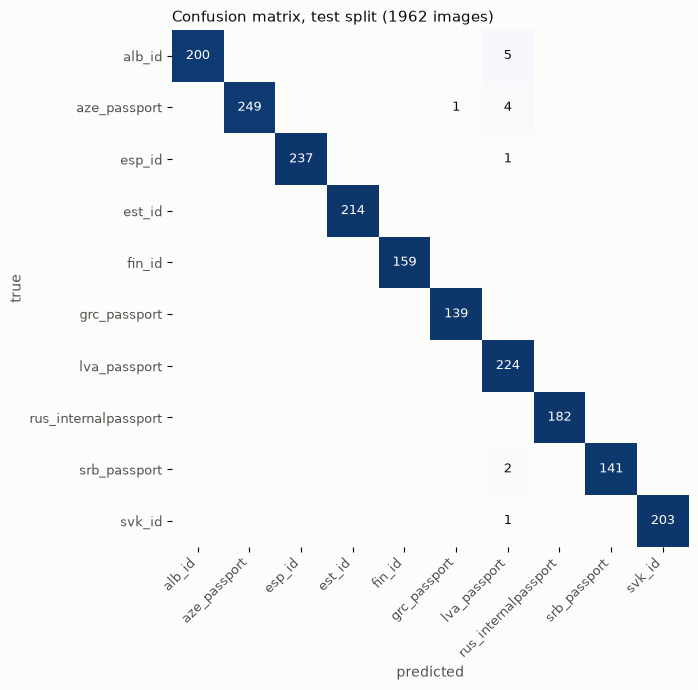

In [13]:
cm = confusion_matrix(test["doc_type"], test["pred"], labels=CLASS_NAMES)
share = cm / cm.sum(axis=1, keepdims=True)  # colour = share of each true class (row)
ramp = LinearSegmentedColormap.from_list("blue", [SURFACE, "#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"])

fig, ax = plt.subplots(figsize=(8, 7), dpi=100, facecolor=SURFACE)
ax.imshow(share, cmap=ramp, vmin=0, vmax=1)
for i in range(len(CLASS_NAMES)):
    for j in range(len(CLASS_NAMES)):
        if cm[i, j]:
            ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=9, color="#ffffff" if share[i, j] > 0.5 else INK)
ax.set_xticks(range(len(CLASS_NAMES)), CLASS_NAMES, rotation=45, ha="right", fontsize=9, color=INK_2)
ax.set_yticks(range(len(CLASS_NAMES)), CLASS_NAMES, fontsize=9, color=INK_2)
ax.set_xlabel("predicted", color=INK_2)
ax.set_ylabel("true", color=INK_2)
ax.set_title(f"Confusion matrix, test split ({len(test)} images)", loc="left", color=INK, fontsize=11)
for side in ax.spines.values():
    side.set_visible(False)
fig.tight_layout()
fig.savefig(REPORT_DIR / "doc_classifier_confusion_test.png", dpi=150, facecolor=SURFACE)
plt.show()

<!-- id: confusion -->
**Confusion matrix (test).** Almost all images lie on the diagonal (correct). Nearly every error lands in the
`lva_passport` column (13 of 14): when a frame shows no recognisable document, the model falls back on
`lva_passport` with low confidence. Of the 3 errors on frames that do show a document, two Azerbaijani passport
frames went to `lva_passport` and one forged Azerbaijani frame to `grc_passport`; no pair of document types is
systematically confused.

In [14]:
epoch_seconds = {"stage1": [round(s, 1) for s in stage1_seconds], "stage2": [round(s, 1) for s in stage2_seconds]}
metrics = {
    **metadata,
    "test_accuracy": round(float(test_accuracy), 4),
    "test_macro_f1": round(float(test_macro_f1), 4),
    "test_rejected_share": round(float(rejected.mean()), 4),
    "lfw_rejected_share": round(float(np.mean(lfw_conf < threshold)), 4),
    "epochs": {"stage1": len(stage1_seconds), "stage2": len(stage2_seconds)},
    "mean_epoch_seconds": {k: round(float(np.mean(v)), 1) for k, v in epoch_seconds.items()},
    "epoch_seconds": epoch_seconds,
    "peak_memory_gb": round(peak_memory_gb(), 2),
}
(REPORT_DIR / "doc_classifier_metrics.json").write_text(json.dumps(metrics, indent=2))
print(f"time per epoch: stage 1 {metrics['mean_epoch_seconds']['stage1']} s, stage 2 {metrics['mean_epoch_seconds']['stage2']} s")
print(f"peak memory of this notebook process: {metrics['peak_memory_gb']} GB | swap in use now: {swap_used_gb():.1f} GB")
print(f"notebook run time: {(time.perf_counter() - notebook_start) / 60:.1f} min")
for path in sorted(REPORT_DIR.iterdir()):
    print(f"  reports/phase3/{path.name}")

time per epoch: stage 1 102.2 s, stage 2 113.1 s
peak memory of this notebook process: 10.0 GB | swap in use now: 28.6 GB
notebook run time: 34.4 min
  reports/phase3/doc_classifier_accuracy_by_source_label.csv
  reports/phase3/doc_classifier_confidence.png
  reports/phase3/doc_classifier_confusion_test.png
  reports/phase3/doc_classifier_metrics.json
  reports/phase3/doc_classifier_report_test.csv
  reports/phase3/doc_classifier_report_val.csv
  reports/phase3/doc_classifier_stage1_log.csv
  reports/phase3/doc_classifier_stage2_log.csv
  reports/phase3/doc_classifier_training_curves.png
  reports/phase3/pipeline_check.png


<!-- id: summary -->
**Summary (Phase 3, Part A).**
- **Shared input pipeline** (`src/ekyc/tfdata.py`): reads the 512 px cache through `manifest.csv`, keeps the aspect
  ratio with `resize_with_pad`, streams batches from disk (over 1,300 images/s, far more than the GPU needs) and
  augments only the training split, without flips.
- **Document-type classifier** (EfficientNetB0, frozen backbone + new head): **test accuracy 99.29 %, macro F1
  0.993**; 99.85 % on frames that show a document; templates 100 %.
- **Reject rule:** confidence < **0.77** → "unrecognized document". It rejects about 1 % of valid documents and
  every test error, but not every non-document image (16.5 % of face photos pass), so it must be combined with
  the other checks.
- **Fine-tuning** (stage 2) gave no measurable gain and collapsed to `NaN` after one good epoch; the checkpoint and
  early stopping kept the good weights. Part B should add `TerminateOnNaN` and gradient clipping.
- **Data issue found:** about 62 cached clip frames (0.4 %; all genuine; from 41 videos; 16 in test) are black or
  blank because the dataset's automatic crop failed. They should be flagged in the manifest before the forgery
  detector is trained.
- **Cost:** 102 s per epoch in stage 1 and 113 s in stage 2 (slowed by memory pressure); peak memory of the
  training process 10.0 GB.